<a href="https://colab.research.google.com/github/bipbolz/ETL-pipeline-data-iklim/blob/main/ETL_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas Minggu 10 – Implementasi ETL Pipeline
**Mata Kuliah:** Big Data  |  **Kelompok 2**  |  **Studi kasus:** Data Iklim Stasiun Cuaca BMKG

| Komponen | Keterangan |
|---|---|
| Sumber data | `climate_data.csv` (data iklim harian) dan `station_detail.csv` (metadata stasiun), format CSV lokal |
| Extract | Python + pandas |
| Transform | Python + pandas + NumPy (seluruh pembersihan dilakukan **sebelum** data masuk database) |
| Load | Python + psycopg 3, bulk load dengan `COPY` |
| Target storage | PostgreSQL, database `db_iklim` (tabel `dim_station`, `fact_climate_daily`, view `vw_climate_station`) |

Alur notebook mengikuti instruksi tugas: **1. Extract → 2. Transform → 3. Load → 4. Integrasi Pipeline → 5. Testing & Validation.**

> **Cara menjalankan:** nyalakan PostgreSQL (`docker compose up -d` di folder `Source_Code`), pastikan CSV ada di `Dataset/raw/`, lalu pilih *Run All*.

In [28]:
from google.colab import files

uploaded = files.upload()

Saving Tugas_Minggu10_Kelompok2.zip to Tugas_Minggu10_Kelompok2 (1).zip


## 0. Setup dan Konfigurasi

In [52]:

!pip install -q "psycopg[binary]" python-dotenv

import os, sys, json, time, logging, warnings, platform
from pathlib import Path
from datetime import datetime
from getpass import getpass

import numpy as np
import pandas as pd
import psycopg
from psycopg import sql
from dotenv import load_dotenv
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 80)

# ---- Lokasi folder Google Colab ----
BASE_DIR = Path("/content")
DATASET_DIR = BASE_DIR / "Dataset"
RAW_DIR = DATASET_DIR / "raw"
DOC_DIR = BASE_DIR / "Documentation"
LOG_DIR = BASE_DIR / "logs"

RAW_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)
DOC_DIR.mkdir(parents=True, exist_ok=True)

CLIMATE_FILE = RAW_DIR / "climate_data.csv"
STATION_FILE = RAW_DIR / "station_detail.csv"
TRANSFORMED_CSV = DATASET_DIR / "transformed_dataset.csv"

# ---- Koneksi PostgreSQL Neon ----
DATABASE_URL = getpass("Masukkan connection string Neon: ")

# ---- Logging ----
log_file = LOG_DIR / f"etl_{datetime.now():%Y%m%d_%H%M%S}.log"
logging.basicConfig(
    level=logging.INFO,
    force=True,
    format="%(asctime)s | %(levelname)-7s | %(message)s",
    datefmt="%H:%M:%S",
    handlers=[
        logging.FileHandler(log_file, encoding="utf-8"),
        logging.StreamHandler(sys.stdout)
    ]
)
log = logging.getLogger("etl")

print("Python", platform.python_version(),
      "| pandas", pd.__version__,
      "| numpy", np.__version__,
      "| psycopg", psycopg.__version__)

print("Folder kerja:", BASE_DIR)
print("Log file:", log_file.name)
print("Konfigurasi Neon siap digunakan.")


Masukkan connection string Neon: ··········
Python 3.13.18 | pandas 2.2.3 | numpy 2.4.6 | psycopg 3.3.9
Folder kerja: /content
Log file: etl_20261118_162333.log
Konfigurasi Neon siap digunakan.


In [53]:
# ---- Tes koneksi PostgreSQL Neon ----

try:
    with psycopg.connect(DATABASE_URL) as conn:
        db_name, db_user = conn.execute(
            "SELECT current_database(), current_user"
        ).fetchone()

        print("KONEKSI BERHASIL!")
        print("Database:", db_name)
        print("User:", db_user)

except Exception as e:
    print("KONEKSI GAGAL!")
    print("Error:", e)

KONEKSI BERHASIL!
Database: neondb
User: neondb_owner


---
# 1. EXTRACT – Data Extraction

### 1a. Identifikasi sumber data
Kedua sumber adalah file CSV statis yang diletakkan manual di `Dataset/raw/`. Tidak ada API atau database sumber, sehingga
akses cukup dengan membaca file memakai `pandas.read_csv`. File asli **tidak pernah diubah**; hasil ekstraksi hanya disimpan
sementara di memori (DataFrame).

In [54]:
sumber = pd.DataFrame([
    ["climate_data.csv",  "CSV", str(CLIMATE_FILE.relative_to(BASE_DIR.parent)), round(CLIMATE_FILE.stat().st_size/1e6, 2) if CLIMATE_FILE.exists() else None,
     "Data iklim harian per stasiun (fakta)"],
    ["station_detail.csv","CSV", str(STATION_FILE.relative_to(BASE_DIR.parent)), round(STATION_FILE.stat().st_size/1e6, 3) if STATION_FILE.exists() else None,
     "Metadata stasiun (dimensi)"],
], columns=["Sumber", "Format", "Lokasi", "Ukuran (MB)", "Peran"])
sumber

,Sumber,Format,Lokasi,Ukuran (MB),Peran
0,climate_data.csv,CSV,content/Dataset/raw/climate_data.csv,None,Data iklim harian per stasiun (fakta)
1,station_detail.csv,CSV,content/Dataset/raw/station_detail.csv,None,Metadata stasiun (dimensi)


### 1b. Melakukan ekstraksi data
Fungsi `extract()` memeriksa keberadaan file, membaca dengan **tipe data eksplisit** (hemat memori dan tidak ada tebakan tipe),
mencoba encoding `utf-8-sig` lalu `latin-1`, dan memastikan seluruh kolom wajib tersedia. `date` dan `ddd_car` sengaja dibaca
sebagai teks karena dibersihkan pada tahap Transform.

In [55]:

import zipfile
from pathlib import Path

# Ekstraksi ZIP
zip_path = Path("/content/Tugas_Minggu10_Kelompok2.zip")

if zip_path.exists():
    print(f"Mengekstrak {zip_path.name}...")
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall("/content")
    print("Ekstraksi selesai!")

# Konfigurasi lokasi dataset
BASE_DIR = Path("/content/Tugas_Minggu10_Kelompok2")
DATASET_DIR = BASE_DIR / "Dataset"
RAW_DIR = DATASET_DIR / "raw"

CLIMATE_FILE = RAW_DIR / "climate_data.csv"
STATION_FILE = RAW_DIR / "station_detail.csv"
TRANSFORMED_CSV = DATASET_DIR / "transformed_dataset.csv"

# Kolom dataset
CLIMATE_COLS = [
    "date", "Tn", "Tx", "Tavg", "RH_avg", "RR",
    "ss", "ff_x", "ddd_x", "ff_avg", "ddd_car", "station_id"
]

STATION_COLS = [
    "station_id", "station_name", "region_name",
    "latitude", "longitude", "region_id", "province_id"
]

CLIMATE_DTYPES = {
    "date": "string", "Tn": "float64", "Tx": "float64",
    "Tavg": "float64", "RH_avg": "float64", "RR": "float64",
    "ss": "float64", "ff_x": "float64", "ddd_x": "float64",
    "ff_avg": "float64", "ddd_car": "string", "station_id": "int64"
}

STATION_DTYPES = {
    "station_id": "int64", "station_name": "string",
    "region_name": "string", "latitude": "float64",
    "longitude": "float64", "region_id": "int64",
    "province_id": "int64"
}

def read_source(path, dtypes, cols):
    if not path.exists():
        raise FileNotFoundError(f"File tidak ditemukan: {path}")

    if path.stat().st_size == 0:
        raise ValueError(f"File kosong: {path}")

    for enc in ("utf-8-sig", "latin-1"):
        try:
            df = pd.read_csv(path, dtype=dtypes, encoding=enc)
            break
        except UnicodeDecodeError:
            log.warning("Encoding %s gagal untuk %s", enc, path.name)
    else:
        raise ValueError(f"Tidak bisa membaca {path.name}")

    missing = [c for c in cols if c not in df.columns]
    if missing:
        raise ValueError(f"{path.name}: kolom wajib hilang {missing}")

    return df[cols]

def extract():
    log.info("Proses Extract dimulai")

    climate = read_source(CLIMATE_FILE, CLIMATE_DTYPES, CLIMATE_COLS)
    station = read_source(STATION_FILE, STATION_DTYPES, STATION_COLS)

    log.info(
        "Data berhasil diekstraksi: climate=%s baris x %s kolom | station=%s baris x %s kolom",
        f"{len(climate):,}", climate.shape[1],
        f"{len(station):,}", station.shape[1]
    )

    return climate, station

# Periksa lokasi file
print("Climate ditemukan:", CLIMATE_FILE.exists())
print("Station ditemukan:", STATION_FILE.exists())

# Jalankan Extract
climate_raw, station_raw = extract()


Mengekstrak Tugas_Minggu10_Kelompok2.zip...
Ekstraksi selesai!
Climate ditemukan: True
Station ditemukan: True
16:25:31 | INFO    | Proses Extract dimulai
16:25:33 | INFO    | Data berhasil diekstraksi: climate=589,265 baris x 12 kolom | station=192 baris x 7 kolom


### 1c. Pemeriksaan awal data
Pemeriksaan minimal: jumlah baris/kolom, nama kolom, tipe data, contoh baris, missing values, duplikat, dan ketidakkonsistenan.

In [56]:
def inspect_df(name, df, key=None):
    print("="*90); print(f"{name}: {df.shape[0]:,} baris x {df.shape[1]} kolom"); print("="*90)
    info = pd.DataFrame({"tipe_data": df.dtypes.astype(str),
                         "kosong": df.isna().sum(),
                         "kosong_%": (df.isna().mean()*100).round(2),
                         "nilai_unik": df.nunique()})
    display(info)
    print("\nContoh 5 baris pertama:"); display(df.head())
    dup_full = int(df.duplicated().sum())
    dup_key = int(df.duplicated(key).sum()) if key else None
    print(f"\nDuplikat baris penuh      : {dup_full}")
    if key: print(f"Duplikat kunci {key} : {dup_key}")
    return info

info_climate = inspect_df("climate_data.csv", climate_raw, key=["station_id", "date"])

climate_data.csv: 589,265 baris x 12 kolom


,tipe_data,kosong,kosong_%,nilai_unik
date,string,0,0.00,4018
Tn,float64,23383,3.97,218
Tx,float64,37736,6.40,254
Tavg,float64,45105,7.65,202
RH_avg,float64,48182,8.18,81
RR,float64,125384,21.28,1734
ss,float64,43721,7.42,188
ff_x,float64,10214,1.73,70
ddd_x,float64,13128,2.23,373
ff_avg,float64,10127,1.72,57



Contoh 5 baris pertama:


,date,Tn,Tx,Tavg,RH_avg,RR,ss,ff_x,ddd_x,ff_avg,ddd_car,station_id
0,01-01-2010,21.4,30.2,27.1,82.0,9.0,0.5,7.0,90.0,5.0,E,96001
1,02-01-2010,21.0,29.6,25.7,95.0,24.0,0.2,6.0,90.0,4.0,E,96001
2,03-01-2010,20.2,26.8,24.5,98.0,63.0,0.0,5.0,90.0,4.0,E,96001
3,04-01-2010,21.0,29.2,25.8,90.0,0.0,0.1,4.0,225.0,3.0,SW,96001
4,05-01-2010,21.2,30.0,26.7,90.0,2.0,0.4,NaN,NaN,NaN,<NA>,96001



Duplikat baris penuh      : 0
Duplikat kunci ['station_id', 'date'] : 0


In [34]:
info_station = inspect_df("station_detail.csv", station_raw, key=["station_id"])

station_detail.csv: 192 baris x 7 kolom


,tipe_data,kosong,kosong_%,nilai_unik
station_id,int64,0,0.0,192
station_name,string,0,0.0,192
region_name,string,0,0.0,150
latitude,float64,0,0.0,187
longitude,float64,0,0.0,188
region_id,int64,0,0.0,150
province_id,int64,0,0.0,34



Contoh 5 baris pertama:


,station_id,station_name,region_name,latitude,longitude,region_id,province_id
0,96001,Stasiun Meteorologi Maimun Saleh,Kota Sabang,5.87655,95.33785,20,1
1,96003,Balai Besar Meteorologi Klimatologi dan Geofisika Wilayah III,Kab. Badung,-8.73810,115.17860,272,17
2,96004,Balai Besar Meteorologi Klimatologi dan Geofisika Wilayah IV,Kota Makassar,-5.14283,119.45227,412,26
3,96009,Stasiun Meteorologi Malikussaleh,Kab. Aceh Utara,5.22869,96.94749,8,1
4,96011,Stasiun Meteorologi Sultan Iskandar Muda,Kab. Aceh Besar,5.52244,95.41700,6,1



Duplikat baris penuh      : 0
Duplikat kunci ['station_id'] : 0


In [35]:
# ---- Ketidakkonsistenan data ----
pola_tanggal = climate_raw["date"].str.match(r"^\d{2}-\d{2}-\d{4}$").mean() * 100
print(f"[climate] kolom date berformat dd-mm-yyyy (teks): {pola_tanggal:.2f}% baris")
print("[climate] nilai unik ddd_car (repr, terlihat spasi di belakang):")
print("   ", sorted(map(repr, climate_raw["ddd_car"].dropna().unique())))
dc = climate_raw["ddd_car"].dropna()
print(f"[climate] ddd_car yang memiliki spasi di tepi: {int((dc != dc.str.strip()).sum()):,} baris")
n_tepi = int((station_raw['station_name'] != station_raw['station_name'].str.strip()).sum())
n_ganda = int(station_raw['station_name'].str.contains(r"\s{2,}", regex=True).sum())
print(f"[station] station_name dengan spasi di awal/akhir: {n_tepi} | dengan spasi ganda: {n_ganda}")

# ---- Kecocokan kunci antar sumber ----
ids_climate, ids_station = set(climate_raw.station_id), set(station_raw.station_id)
print(f"\n[kunci] stasiun unik di climate: {len(ids_climate)} | di station_detail: {len(ids_station)} | "
      f"cocok: {len(ids_climate & ids_station)} | climate tanpa metadata: {len(ids_climate - ids_station)} | "
      f"metadata tanpa data iklim: {len(ids_station - ids_climate)}")
print(f"[periode] {pd.to_datetime(climate_raw.date, format='%d-%m-%Y').min().date()} s/d "
      f"{pd.to_datetime(climate_raw.date, format='%d-%m-%Y').max().date()}")

[climate] kolom date berformat dd-mm-yyyy (teks): 100.00% baris
[climate] nilai unik ddd_car (repr, terlihat spasi di belakang):
    ["'C '", "'E '", "'N '", "'NE'", "'NW'", "'S '", "'SE'", "'SW'", "'W '"]
[climate] ddd_car yang memiliki spasi di tepi: 432,118 baris
[station] station_name dengan spasi di awal/akhir: 4 | dengan spasi ganda: 1

[kunci] stasiun unik di climate: 173 | di station_detail: 192 | cocok: 173 | climate tanpa metadata: 0 | metadata tanpa data iklim: 19
[periode] 2010-01-01 s/d 2020-12-31


### 1d. Ringkasan kondisi awal data (dicatat sebagai pembanding tahap Transform)

In [39]:
extract_summary = {
    "climate_rows": len(climate_raw), "climate_cols": climate_raw.shape[1],
    "station_rows": len(station_raw), "station_cols": station_raw.shape[1],
    "climate_nulls": {c: int(v) for c, v in climate_raw.isna().sum().items()},
    "climate_dup_full": int(climate_raw.duplicated().sum()),
    "climate_dup_key": int(climate_raw.duplicated(["station_id", "date"]).sum()),
    "station_dup_key": int(station_raw.duplicated("station_id").sum()),
    "stations_in_climate": len(ids_climate), "stations_in_metadata": len(ids_station),
}
pd.Series({k: v for k, v in extract_summary.items() if not isinstance(v, dict)}, name="nilai").to_frame()

,nilai
climate_rows,589265
climate_cols,12
station_rows,192
station_cols,7
climate_dup_full,0
climate_dup_key,0
station_dup_key,0
stations_in_climate,173
stations_in_metadata,192


---
# 2. TRANSFORM – Data Transformation

### 2a. Data Inspection – permasalahan yang ditemukan
Setiap masalah dihitung langsung dari data hasil Extract. Ambang batas aturan dikumpulkan dalam satu dict `RULES`
agar mudah dijelaskan dan diubah.

In [40]:
RULES = {
    "rh_max": 100,        # RH_avg > 100 (%)            -> NULL
    "ddd_x_max": 360,     # ddd_x > 360 (derajat)       -> NULL
    "ss_max": 12,         # ss > 12 jam                 -> NULL
    "rr_min": 0,          # RR < 0                      -> NULL
    "rr_max": 500,        # RR > 500 mm/hari            -> NULL (tidak realistis)
    "wind_max_knot": 60,  # ff_x / ff_avg > 60 knot     -> NULL
    "temp_min": 5,        # suhu < 5 C                  -> NULL (termasuk nilai 0 = kode salah input)
    "temp_max": 45,       # suhu > 45 C                 -> NULL (mis. 246, 334)
}
VALID_DIRECTIONS = {"N", "NE", "E", "SE", "S", "SW", "W", "NW", "C"}   # C = calm (tenang)

r = climate_raw
temp_cells = sum(int(((r[c] < RULES["temp_min"]) | (r[c] > RULES["temp_max"])).sum()) for c in ["Tn", "Tx", "Tavg"])
sn = station_raw["station_name"]

rows = [
 ["(semua kolom)", "Duplicate Records", "Baris duplikat penuh dan duplikat (station_id, date)", extract_summary["climate_dup_full"] + extract_summary["climate_dup_key"], "Tidak ada; penghapusan duplikat tidak diperlukan"],
 ["date", "Incorrect Data Types", "Tanggal berupa teks 'dd-mm-yyyy'", int(r.date.notna().sum()), "Tidak bisa diurutkan, difilter, atau diagregasi sebagai waktu"],
 ["ddd_car", "Inconsistent Data", "Spasi di belakang ('N ', 'E ')", int((dc != dc.str.strip()).sum()), "Kategori arah angin terpecah: 'N' dan 'N ' dianggap berbeda"],
 ["RH_avg", "Invalid Values", f"> {RULES['rh_max']} % (maks {r.RH_avg.max():g})", int((r.RH_avg > RULES['rh_max']).sum()), "Kelembapan tidak mungkin >100%; merusak rata-rata"],
 ["ddd_x", "Invalid Values", f"> {RULES['ddd_x_max']} derajat", int((r.ddd_x > RULES['ddd_x_max']).sum()), "Arah angin hanya 0-360 derajat"],
 ["ss", "Invalid Values", f"> {RULES['ss_max']} jam penyinaran", int((r.ss > RULES['ss_max']).sum()), "Penyinaran per hari tidak mungkin >12 jam"],
 ["RR", "Invalid Values", "Curah hujan negatif", int((r.RR < RULES['rr_min']).sum()), "Curah hujan tidak boleh negatif"],
 ["RR", "Invalid Values", f"> {RULES['rr_max']} mm/hari (maks {r.RR.max():g})", int((r.RR > RULES['rr_max']).sum()), "Tidak realistis, mendistorsi total hujan"],
 ["ff_x", "Invalid Values", f"> {RULES['wind_max_knot']} knot (maks {r.ff_x.max():g})", int((r.ff_x > RULES['wind_max_knot']).sum()), "Kecepatan angin ekstrem tidak masuk akal"],
 ["ff_avg", "Invalid Values", f"> {RULES['wind_max_knot']} knot (maks {r.ff_avg.max():g})", int((r.ff_avg > RULES['wind_max_knot']).sum()), "Sama seperti ff_x"],
 ["Tn, Tx, Tavg", "Invalid Values", f"Suhu di luar {RULES['temp_min']}-{RULES['temp_max']} C (mis. 246, 334, 0)", temp_cells, "Mendistorsi rata-rata suhu (jumlah sel, bukan baris)"],
 ["Tn, Tx", "Inconsistent Data", "Tn lebih besar dari Tx (data mentah)", int((r.Tn > r.Tx).sum()), "Suhu minimum tidak mungkin melebihi maksimum"],
 ["station_name", "Inconsistent Data", "Spasi ganda atau spasi di awal/akhir", int((sn != sn.str.strip().str.replace(r'\s+', ' ', regex=True)).sum()), "Nama sama bisa terbaca berbeda saat pengelompokan"],
]
for c in ["RR", "RH_avg", "Tavg", "ss", "Tn", "Tx", "ff_x", "ff_avg", "ddd_x", "ddd_car"]:
    n = int(r[c].isna().sum())
    if n:
        rows.append([c, "Missing Values", f"{n/len(r)*100:.2f}% kosong", n, "Tidak diisi (imputasi) agar tidak memalsukan data; dicatat apa adanya"])
problems = pd.DataFrame(rows, columns=["Atribut", "Jenis masalah", "Karakteristik", "Jumlah", "Dampak"])
problems

,Atribut,Jenis masalah,Karakteristik,Jumlah,Dampak
0,(semua kolom),Duplicate Records,"Baris duplikat penuh dan duplikat (station_id, date)",0,Tidak ada; penghapusan duplikat tidak diperlukan
1,date,Incorrect Data Types,Tanggal berupa teks 'dd-mm-yyyy',589265,"Tidak bisa diurutkan, difilter, atau diagregasi sebagai waktu"
2,ddd_car,Inconsistent Data,"Spasi di belakang ('N ', 'E ')",432118,Kategori arah angin terpecah: 'N' dan 'N ' dianggap berbeda
3,RH_avg,Invalid Values,> 100 % (maks 7520),7,Kelembapan tidak mungkin >100%; merusak rata-rata
4,ddd_x,Invalid Values,> 360 derajat,541,Arah angin hanya 0-360 derajat
5,ss,Invalid Values,> 12 jam penyinaran,206,Penyinaran per hari tidak mungkin >12 jam
6,RR,Invalid Values,Curah hujan negatif,7,Curah hujan tidak boleh negatif
7,RR,Invalid Values,> 500 mm/hari (maks 1965.5),4,"Tidak realistis, mendistorsi total hujan"
8,ff_x,Invalid Values,> 60 knot (maks 185),51,Kecepatan angin ekstrem tidak masuk akal
9,ff_avg,Invalid Values,> 60 knot (maks 160),12,Sama seperti ff_x


**Irrelevant Attributes:** seluruh 12 kolom iklim dan 7 kolom metadata dipakai pada analisis dashboard, sehingga tidak ada kolom yang dibuang.

### 2b. Data Cleaning – teknik yang dipilih dan alasannya

| Masalah | Teknik | Alasan |
|---|---|---|
| `date` teks | Data Type Conversion ke `datetime` | Agar bisa diurutkan, difilter, dan diagregasi per tahun/bulan |
| `ddd_car` berspasi | Data Standardization (`strip`) | Menyatukan kategori. Nilai `C` (calm) **dipertahankan** karena bermakna |
| Nilai mustahil (RH, ddd_x, ss, RR, ff, suhu) | Invalid Data Handling: diubah menjadi **NULL** | Hanya sel yang salah yang dikosongkan; baris dipertahankan karena kolom lain pada baris itu masih valid |
| `Tn > Tx` | Hanya diberi **flag** | Tidak diketahui mana yang salah (Tn atau Tx), sehingga nilai tidak diubah |
| Missing values | **Tidak diimputasi** | Proporsi kosong besar (RR 21%); mengisi dengan mean/median akan memalsukan pola hujan |
| Nama stasiun | Data Standardization (trim + spasi ganda) | Konsistensi nama |
| Duplikat | Pengecekan, tidak ada yang dihapus | 0 duplikat ditemukan |

### 2c. Data Transformation
- **Data Integration:** menggabungkan data iklim dengan metadata stasiun lewat `station_id` (terbukti 1:1, 173 stasiun cocok seluruhnya).
- **Feature Creation:** kolom flag kualitas (`flag_*`, `dq_issue_count`, `has_dq_issue`) agar baris bermasalah terlihat di dashboard, serta `year` dan `month` untuk agregasi waktu.
- **Attribute Transformation:** nama kolom dibuat huruf kecil (`Tn` → `tn`) agar konsisten di PostgreSQL; `ddd_x` menjadi bilangan bulat.

In [41]:
def _clean_text(s):
    return s.str.strip().str.replace(r"\s+", " ", regex=True)

def _null_out(df, col, mask, invalid, rule):
    mask = mask.fillna(False)
    n = int(mask.sum())
    df.loc[mask, col] = np.nan
    invalid[rule] = n
    log.info("  %-34s -> %s nilai di-NULL-kan", rule, f"{n:,}")
    return mask

def transform(climate_raw, station_raw, save_csv=True):
    log.info("Proses Transform dimulai")
    rows_before = len(climate_raw)
    df = climate_raw.copy()
    df.columns = [c.lower() for c in df.columns]
    nulls_before = {c: int(df[c].isna().sum()) for c in df.columns}
    invalid = {}

    # (1) date: teks dd-mm-yyyy -> datetime
    df["date"] = pd.to_datetime(df["date"].str.strip(), format="%d-%m-%Y", errors="coerce")
    bad_dates = int(df["date"].isna().sum())
    if bad_dates:
        log.warning("  %s tanggal tidak valid -> baris dibuang", bad_dates)
        df = df.dropna(subset=["date"])
    invalid["date tidak valid (baris dibuang)"] = bad_dates

    # (2) ddd_car: strip spasi, pertahankan 'C'
    df["ddd_car"] = df["ddd_car"].str.strip().str.upper()
    df.loc[df["ddd_car"] == "", "ddd_car"] = pd.NA
    unknown_dir = df["ddd_car"].notna() & ~df["ddd_car"].isin(VALID_DIRECTIONS)
    invalid["ddd_car kode tidak dikenal"] = int(unknown_dir.sum())
    df.loc[unknown_dir, "ddd_car"] = pd.NA

    log.info("Aturan validasi (nilai invalid -> NULL, baris dipertahankan):")
    df["flag_rh_invalid"] = _null_out(df, "rh_avg", df["rh_avg"] > RULES["rh_max"], invalid, "rh_avg > 100")
    m = _null_out(df, "ddd_x", df["ddd_x"] > RULES["ddd_x_max"], invalid, "ddd_x > 360")
    df["flag_wind_dir_invalid"] = m | unknown_dir
    df["flag_sunshine_invalid"] = _null_out(df, "ss", df["ss"] > RULES["ss_max"], invalid, "ss > 12 jam")
    m1 = _null_out(df, "rr", df["rr"] < RULES["rr_min"], invalid, "rr < 0")
    m2 = _null_out(df, "rr", df["rr"] > RULES["rr_max"], invalid, "rr > 500 mm")
    df["flag_rain_invalid"] = m1 | m2
    m1 = _null_out(df, "ff_x", df["ff_x"] > RULES["wind_max_knot"], invalid, "ff_x > 60 knot")
    m2 = _null_out(df, "ff_avg", df["ff_avg"] > RULES["wind_max_knot"], invalid, "ff_avg > 60 knot")
    df["flag_wind_speed_invalid"] = m1 | m2
    tflag = pd.Series(False, index=df.index)
    for col in ["tn", "tx", "tavg"]:
        bad = (df[col] < RULES["temp_min"]) | (df[col] > RULES["temp_max"])
        tflag |= _null_out(df, col, bad, invalid, f"{col} di luar 5-45 C")
    df["flag_temp_invalid"] = tflag

    # Tn > Tx dicek SETELAH suhu ekstrem dibuang; hanya di-flag
    df["flag_tn_gt_tx"] = (df["tn"] > df["tx"]).fillna(False)
    invalid["tn > tx (hanya flag)"] = int(df["flag_tn_gt_tx"].sum())
    log.info("  %-34s -> %s baris di-flag (nilai tidak diubah)", "tn > tx", f"{invalid['tn > tx (hanya flag)']:,}")

    flag_cols = [c for c in df.columns if c.startswith("flag_")]
    df["dq_issue_count"] = df[flag_cols].sum(axis=1).astype("int16")
    df["has_dq_issue"] = df["dq_issue_count"] > 0
    df["ddd_x"] = df["ddd_x"].round().astype("Int64")

    dup = int(df.duplicated(["station_id", "date"]).sum())
    if dup:
        df = df.drop_duplicates(["station_id", "date"], keep="first")
    invalid["duplikat (station_id,date) dibuang"] = dup
    df = df.sort_values(["station_id", "date"]).reset_index(drop=True)

    # Metadata stasiun
    st = station_raw.copy()
    name_fixed = int((st["station_name"] != _clean_text(st["station_name"])).sum())
    st["station_name"] = _clean_text(st["station_name"])
    st["region_name"] = _clean_text(st["region_name"])
    st = st.drop_duplicates("station_id", keep="first")

    # Integrasi: merge climate x station
    climate_ids, station_ids = set(df["station_id"]), set(st["station_id"])
    st["has_climate_data"] = st["station_id"].isin(climate_ids)
    num_cols = ["tn", "tx", "tavg", "rh_avg", "rr", "ss", "ff_x", "ddd_x", "ff_avg"]
    fact_cols = ["station_id", "date"] + num_cols + ["ddd_car"] + flag_cols + ["dq_issue_count", "has_dq_issue"]
    fact = df[fact_cols]
    dim = st[["station_id", "station_name", "region_name", "latitude", "longitude", "region_id",
              "province_id", "has_climate_data"]].sort_values("station_id").reset_index(drop=True)

    merged = fact.merge(dim.drop(columns="has_climate_data"), on="station_id", how="left",
                        indicator=True, validate="many_to_one")
    rows_matched = int((merged["_merge"] == "both").sum())
    merged = merged.drop(columns="_merge")
    merged["year"] = merged["date"].dt.year.astype("int16")
    merged["month"] = merged["date"].dt.month.astype("int8")
    front = ["station_id", "date", "year", "month", "station_name", "region_name", "latitude", "longitude",
             "region_id", "province_id"]
    merged = merged[front + [c for c in merged.columns if c not in front]]

    null_cols = num_cols + ["ddd_car"]
    nulls_after = {c: int(fact[c].isna().sum()) for c in null_cols}
    report = {
        "rows_before": rows_before, "rows_after": int(len(fact)), "cols_before": climate_raw.shape[1],
        "cols_after_fact": fact.shape[1], "cols_after_merged": merged.shape[1],
        "dim_rows": int(len(dim)), "date_min": str(fact["date"].min().date()), "date_max": str(fact["date"].max().date()),
        "nulls_before": {c: nulls_before[c] for c in null_cols}, "nulls_after": nulls_after,
        "invalid_by_rule": invalid, "flag_counts": {c: int(fact[c].sum()) for c in flag_cols},
        "rows_with_dq_issue": int(fact["has_dq_issue"].sum()), "station_names_cleaned": name_fixed,
        "merge": {"stations_in_climate": len(climate_ids), "stations_in_metadata": len(station_ids),
                  "stations_merged": len(climate_ids & station_ids),
                  "station_id_without_metadata": sorted(int(x) for x in climate_ids - station_ids),
                  "metadata_without_climate": len(station_ids - climate_ids),
                  "rows_merged": rows_matched, "rows_unmatched": int(len(fact) - rows_matched)},
        "rules": RULES,
    }
    if save_csv:
        merged.to_csv(TRANSFORMED_CSV, index=False, date_format="%Y-%m-%d")
        log.info("Dataset hasil transformasi disimpan: %s", TRANSFORMED_CSV.name)
    log.info("Data berhasil dibersihkan dan ditransformasi: %s baris (sebelum %s)", f"{len(fact):,}", f"{rows_before:,}")
    return {"fact": fact, "dim": dim, "merged": merged, "report": report}

res = transform(climate_raw, station_raw)
fact, dim, merged, report = res["fact"], res["dim"], res["merged"], res["report"]

15:34:04 | INFO    | Proses Transform dimulai
15:34:06 | INFO    | Aturan validasi (nilai invalid -> NULL, baris dipertahankan):
15:34:06 | INFO    |   rh_avg > 100                       -> 7 nilai di-NULL-kan
15:34:06 | INFO    |   ddd_x > 360                        -> 541 nilai di-NULL-kan
15:34:06 | INFO    |   ss > 12 jam                        -> 206 nilai di-NULL-kan
15:34:06 | INFO    |   rr < 0                             -> 7 nilai di-NULL-kan
15:34:06 | INFO    |   rr > 500 mm                        -> 4 nilai di-NULL-kan
15:34:06 | INFO    |   ff_x > 60 knot                     -> 51 nilai di-NULL-kan
15:34:06 | INFO    |   ff_avg > 60 knot                   -> 12 nilai di-NULL-kan
15:34:06 | INFO    |   tn di luar 5-45 C                  -> 78 nilai di-NULL-kan
15:34:06 | INFO    |   tx di luar 5-45 C                  -> 75 nilai di-NULL-kan
15:34:06 | INFO    |   tavg di luar 5-45 C                -> 6 nilai di-NULL-kan
15:34:06 | INFO    |   tn > tx                       

### 2d. Data Validation – validasi hasil transformasi

In [42]:
def validate_transform(fact, dim, merged, report, climate_raw):
    checks = []
    def add(name, ok, detail): checks.append([name, "LULUS" if ok else "GAGAL", detail])
    add("Jumlah baris tidak berubah", len(fact) == len(climate_raw), f"{len(climate_raw):,} -> {len(fact):,}")
    add("Hasil merge tidak menggandakan baris", len(merged) == len(fact), f"fact {len(fact):,} | merged {len(merged):,}")
    add("Tidak ada duplikat (station_id, date)", not fact.duplicated(["station_id", "date"]).any(), "0 duplikat")
    add("Tipe date = datetime", str(fact["date"].dtype).startswith("datetime64"), str(fact["date"].dtype))
    add("rh_avg dalam 0-100", fact.rh_avg.max() <= 100 and fact.rh_avg.min() >= 0, f"min {fact.rh_avg.min()}, maks {fact.rh_avg.max()}")
    add("ddd_x dalam 0-360", fact.ddd_x.max() <= 360 and fact.ddd_x.min() >= 0, f"min {fact.ddd_x.min()}, maks {fact.ddd_x.max()}")
    add("ss dalam 0-12", fact.ss.max() <= 12 and fact.ss.min() >= 0, f"min {fact.ss.min()}, maks {fact.ss.max()}")
    add("rr dalam 0-500", fact.rr.min() >= 0 and fact.rr.max() <= 500, f"min {fact.rr.min()}, maks {fact.rr.max()}")
    add("ff_x dan ff_avg <= 60", max(fact.ff_x.max(), fact.ff_avg.max()) <= 60, f"maks ff_x {fact.ff_x.max()}, ff_avg {fact.ff_avg.max()}")
    add("tn, tx, tavg dalam 5-45", all(fact[c].dropna().between(5, 45).all() for c in ["tn", "tx", "tavg"]) , f"min {min(fact[c].min() for c in ['tn','tx','tavg'])}, maks {max(fact[c].max() for c in ['tn','tx','tavg'])}")
    add("ddd_car tanpa spasi, kode valid", set(fact.ddd_car.dropna().unique()) <= VALID_DIRECTIONS, ", ".join(sorted(fact.ddd_car.dropna().unique())))
    add("Nilai calm 'C' dipertahankan", int((fact.ddd_car == "C").sum()) == int((climate_raw.ddd_car.str.strip() == "C").sum()), f"{int((fact.ddd_car == 'C').sum()):,} baris")
    add("Nama stasiun rapi", not dim.station_name.str.contains(r"\s{2,}|^\s|\s$", regex=True).any(), "0 nama bermasalah")
    add("has_dq_issue konsisten dengan flag", ((fact.dq_issue_count > 0) == fact.has_dq_issue).all(), f"{int(fact.has_dq_issue.sum()):,} baris bermasalah")
    add("Semua station_id punya metadata", report["merge"]["rows_unmatched"] == 0, f"{report['merge']['rows_unmatched']} baris tanpa metadata")
    out = pd.DataFrame(checks, columns=["Pemeriksaan", "Status", "Detail"])
    assert (out.Status == "LULUS").all(), "Ada validasi yang gagal:\n" + out[out.Status == "GAGAL"].to_string()
    return out

validasi = validate_transform(fact, dim, merged, report, climate_raw)
validasi

,Pemeriksaan,Status,Detail
0,Jumlah baris tidak berubah,LULUS,"589,265 -> 589,265"
1,Hasil merge tidak menggandakan baris,LULUS,"fact 589,265 | merged 589,265"
2,"Tidak ada duplikat (station_id, date)",LULUS,0 duplikat
3,Tipe date = datetime,LULUS,datetime64[ns]
4,rh_avg dalam 0-100,LULUS,"min 24.0, maks 100.0"
5,ddd_x dalam 0-360,LULUS,"min 0, maks 360"
6,ss dalam 0-12,LULUS,"min 0.0, maks 12.0"
7,rr dalam 0-500,LULUS,"min 0.0, maks 470.0"
8,ff_x dan ff_avg <= 60,LULUS,"maks ff_x 57.0, ff_avg 59.0"
9,"tn, tx, tavg dalam 5-45",LULUS,"min 5.0, maks 42.6"


### 2e. Perbandingan kondisi data sebelum dan sesudah transformasi

In [43]:
umum = pd.DataFrame([
    ["Jumlah baris data iklim", f"{len(climate_raw):,}", f"{len(fact):,}", "Tidak berubah: tidak ada baris dibuang (nilai invalid hanya di-NULL-kan)"],
    ["Jumlah kolom data iklim", climate_raw.shape[1], f"{fact.shape[1]} (tabel fakta) / {merged.shape[1]} (dataset gabungan)",
     "Bertambah: 9 kolom flag/kualitas; dataset gabungan +6 atribut stasiun, year, month"],
    ["Duplikat (station_id, date)", extract_summary["climate_dup_key"], int(fact.duplicated(["station_id", "date"]).sum()), "Tidak ada duplikat sejak awal"],
    ["Baris metadata stasiun", len(station_raw), len(dim), "Tidak berubah; ditambah kolom has_climate_data"],
    ["Nama stasiun dirapikan", "-", report["station_names_cleaned"], "Spasi ganda / tepi dibersihkan"],
], columns=["Aspek", "Sebelum", "Sesudah", "Penjelasan"])
display(umum)

cmp_null = pd.DataFrame({"NULL sebelum": report["nulls_before"], "NULL sesudah": report["nulls_after"]})
cmp_null["Bertambah (validasi)"] = cmp_null["NULL sesudah"] - cmp_null["NULL sebelum"]
cmp_null["% kosong sesudah"] = (cmp_null["NULL sesudah"] / len(fact) * 100).round(2)
display(cmp_null)

rule_tbl = pd.DataFrame(list(report["invalid_by_rule"].items()), columns=["Aturan", "Jumlah"])
display(rule_tbl)
print(f"Baris dengan minimal satu masalah kualitas: {report['rows_with_dq_issue']:,} "
      f"({report['rows_with_dq_issue']/len(fact)*100:.2f}%)")
print("\nContoh 5 baris dataset hasil transformasi:")
display(merged.head())
print(f"File tersimpan: {TRANSFORMED_CSV.name}  ({TRANSFORMED_CSV.stat().st_size/1e6:.1f} MB)")

,Aspek,Sebelum,Sesudah,Penjelasan
0,Jumlah baris data iklim,"589,265","589,265",Tidak berubah: tidak ada baris dibuang (nilai invalid hanya di-NULL-kan)
1,Jumlah kolom data iklim,12,21 (tabel fakta) / 29 (dataset gabungan),"Bertambah: 9 kolom flag/kualitas; dataset gabungan +6 atribut stasiun, year,..."
2,"Duplikat (station_id, date)",0,0,Tidak ada duplikat sejak awal
3,Baris metadata stasiun,192,192,Tidak berubah; ditambah kolom has_climate_data
4,Nama stasiun dirapikan,-,5,Spasi ganda / tepi dibersihkan


,NULL sebelum,NULL sesudah,Bertambah (validasi),% kosong sesudah
tn,23383,23461,78,3.98
tx,37736,37811,75,6.42
tavg,45105,45111,6,7.66
rh_avg,48182,48189,7,8.18
rr,125384,125395,11,21.28
ss,43721,43927,206,7.45
ff_x,10214,10265,51,1.74
ddd_x,13128,13669,541,2.32
ff_avg,10127,10139,12,1.72
ddd_car,13739,13739,0,2.33


,Aturan,Jumlah
0,date tidak valid (baris dibuang),0
1,ddd_car kode tidak dikenal,0
2,rh_avg > 100,7
3,ddd_x > 360,541
4,ss > 12 jam,206
5,rr < 0,7
6,rr > 500 mm,4
7,ff_x > 60 knot,51
8,ff_avg > 60 knot,12
9,tn di luar 5-45 C,78


Baris dengan minimal satu masalah kualitas: 1,453 (0.25%)

Contoh 5 baris dataset hasil transformasi:


,station_id,date,year,month,station_name,region_name,latitude,longitude,region_id,province_id,tn,tx,tavg,rh_avg,rr,ss,ff_x,ddd_x,ff_avg,ddd_car,flag_rh_invalid,flag_wind_dir_invalid,flag_sunshine_invalid,flag_rain_invalid,flag_wind_speed_invalid,flag_temp_invalid,flag_tn_gt_tx,dq_issue_count,has_dq_issue
0,96001,2010-01-01,2010,1,Stasiun Meteorologi Maimun Saleh,Kota Sabang,5.87655,95.33785,20,1,21.4,30.2,27.1,82.0,9.0,0.5,7.0,90,5.0,E,False,False,False,False,False,False,False,0,False
1,96001,2010-01-02,2010,1,Stasiun Meteorologi Maimun Saleh,Kota Sabang,5.87655,95.33785,20,1,21.0,29.6,25.7,95.0,24.0,0.2,6.0,90,4.0,E,False,False,False,False,False,False,False,0,False
2,96001,2010-01-03,2010,1,Stasiun Meteorologi Maimun Saleh,Kota Sabang,5.87655,95.33785,20,1,20.2,26.8,24.5,98.0,63.0,0.0,5.0,90,4.0,E,False,False,False,False,False,False,False,0,False
3,96001,2010-01-04,2010,1,Stasiun Meteorologi Maimun Saleh,Kota Sabang,5.87655,95.33785,20,1,21.0,29.2,25.8,90.0,0.0,0.1,4.0,225,3.0,SW,False,False,False,False,False,False,False,0,False
4,96001,2010-01-05,2010,1,Stasiun Meteorologi Maimun Saleh,Kota Sabang,5.87655,95.33785,20,1,21.2,30.0,26.7,90.0,2.0,0.4,NaN,<NA>,NaN,<NA>,False,False,False,False,False,False,False,0,False


File tersimpan: transformed_dataset.csv  (109.1 MB)


---
# 3. LOAD – Data Loading ke PostgreSQL

### 3a. Menghubungkan program dengan target storage
Target storage adalah **PostgreSQL** (sesuai rancangan Minggu 9). Koneksi memakai library `psycopg` 3 dengan parameter dari `.env`.
Database `db_iklim` dibuat otomatis bila belum ada.

In [59]:

def test_connection():
    with psycopg.connect(DATABASE_URL) as conn:
        version = conn.execute(
            "SELECT version()"
        ).fetchone()[0]

        dbname, user = conn.execute(
            "SELECT current_database(), current_user"
        ).fetchone()

    return {
        "database": dbname,
        "user": user,
        "host": "Neon PostgreSQL",
        "baru_dibuat": False,
        "versi": version.split(",")[0]
    }


bukti_koneksi = test_connection()

pd.Series(
    bukti_koneksi,
    name="bukti koneksi"
).to_frame()


,bukti koneksi
database,neondb
user,neondb_owner
host,Neon PostgreSQL
baru_dibuat,False
versi,PostgreSQL 18.7 (a21afb5) on aarch64-unknown-linux-gnu


In [49]:
!pip install -q "psycopg[binary]"

In [45]:
print(DB)

{'host': 'localhost', 'port': 5432, 'dbname': 'db_iklim', 'user': 'postgres', 'password': 'postgres123'}


### 3b. Struktur penyimpanan

| Objek | Isi | Kunci |
|---|---|---|
| `dim_station` | metadata 192 stasiun | PRIMARY KEY `station_id` |
| `fact_climate_daily` | data iklim harian bersih + flag kualitas | PRIMARY KEY (`station_id`, `date`), FOREIGN KEY ke `dim_station` |
| `vw_climate_station` | view gabungan fakta + stasiun + `year`, `month` untuk dashboard | - |

Tipe data: `DATE` (tanggal), `INTEGER`/`SMALLINT` (id, arah angin), `NUMERIC` (suhu, kelembapan, hujan, penyinaran, angin),
`TEXT`/`VARCHAR` (nama, arah), `BOOLEAN` (flag). Terdapat `CHECK constraint` (mis. `rh_avg` 0-100) sebagai pengaman kualitas di level database.

In [60]:
DDL = """
CREATE TABLE IF NOT EXISTS dim_station (
    station_id       INTEGER PRIMARY KEY,
    station_name     TEXT        NOT NULL,
    region_name      TEXT,
    latitude         NUMERIC(10,6),
    longitude        NUMERIC(10,6),
    region_id        INTEGER,
    province_id      INTEGER,
    has_climate_data BOOLEAN     NOT NULL DEFAULT FALSE
);
CREATE TABLE IF NOT EXISTS fact_climate_daily (
    station_id              INTEGER  NOT NULL REFERENCES dim_station (station_id),
    date                    DATE     NOT NULL,
    tn                      NUMERIC(4,1),
    tx                      NUMERIC(4,1),
    tavg                    NUMERIC(4,1),
    rh_avg                  NUMERIC(5,1) CHECK (rh_avg BETWEEN 0 AND 100),
    rr                      NUMERIC(6,1) CHECK (rr >= 0),
    ss                      NUMERIC(3,1) CHECK (ss BETWEEN 0 AND 12),
    ff_x                    NUMERIC(5,1),
    ddd_x                   SMALLINT     CHECK (ddd_x BETWEEN 0 AND 360),
    ff_avg                  NUMERIC(5,1),
    ddd_car                 VARCHAR(2),
    flag_rh_invalid         BOOLEAN  NOT NULL,
    flag_wind_dir_invalid   BOOLEAN  NOT NULL,
    flag_sunshine_invalid   BOOLEAN  NOT NULL,
    flag_rain_invalid       BOOLEAN  NOT NULL,
    flag_wind_speed_invalid BOOLEAN  NOT NULL,
    flag_temp_invalid       BOOLEAN  NOT NULL,
    flag_tn_gt_tx           BOOLEAN  NOT NULL,
    dq_issue_count          SMALLINT NOT NULL,
    has_dq_issue            BOOLEAN  NOT NULL,
    PRIMARY KEY (station_id, date)
);
CREATE INDEX IF NOT EXISTS idx_fact_climate_date ON fact_climate_daily (date);
CREATE OR REPLACE VIEW vw_climate_station AS
SELECT f.*, EXTRACT(YEAR FROM f.date)::INT AS year, EXTRACT(MONTH FROM f.date)::INT AS month,
       s.station_name, s.region_name, s.latitude, s.longitude, s.region_id, s.province_id
FROM fact_climate_daily f JOIN dim_station s USING (station_id);
"""
DIM_COLS = ["station_id","station_name","region_name","latitude","longitude","region_id","province_id","has_climate_data"]
FACT_COLS = ["station_id","date","tn","tx","tavg","rh_avg","rr","ss","ff_x","ddd_x","ff_avg","ddd_car",
             "flag_rh_invalid","flag_wind_dir_invalid","flag_sunshine_invalid","flag_rain_invalid",
             "flag_wind_speed_invalid","flag_temp_invalid","flag_tn_gt_tx","dq_issue_count","has_dq_issue"]
NUM_COLS = ["tn","tx","tavg","rh_avg","rr","ss","ff_x","ddd_x","ff_avg"]
BOOL_COLS = [c for c in FACT_COLS if c.startswith("flag_")] + ["has_dq_issue"]
print("Skema siap:", len(DDL.splitlines()), "baris DDL | kolom fakta:", len(FACT_COLS), "| kolom dimensi:", len(DIM_COLS))

Skema siap: 40 baris DDL | kolom fakta: 21 | kolom dimensi: 8


### 3c. Proses loading dan mekanisme yang dipilih
**Mekanisme: REPLACE (TRUNCATE lalu COPY) dalam satu transaksi.** Alasannya:
1. Sumber berupa dua file CSV statis (bukan aliran data baru), sehingga memuat ulang seluruh data adalah cara paling sederhana dan benar.
2. **Idempotent:** menjalankan pipeline berulang tidak menggandakan data (append akan menduplikasi, upsert tidak perlu karena tidak ada pembaruan parsial).
3. **Aman:** `TRUNCATE` dan `COPY` berada di satu transaksi; bila terjadi error semuanya di-*rollback* dan data lama tetap utuh.
4. **Cepat:** `COPY ... FROM STDIN` memuat 589 ribu baris jauh lebih cepat daripada `INSERT` per baris.

In [63]:

def load(fact, dim):
    log.info("Proses Load dimulai")

    with psycopg.connect(DATABASE_URL) as conn:
        with conn.cursor() as cur:
            cur.execute(DDL)

            cur.execute(
                "TRUNCATE fact_climate_daily, dim_station"
            )

            _copy_df(cur, "dim_station", dim, DIM_COLS)
            _copy_df(cur, "fact_climate_daily", fact, FACT_COLS)

            n_dim = cur.execute(
                "SELECT COUNT(*) FROM dim_station"
            ).fetchone()[0]

            n_fact = cur.execute(
                "SELECT COUNT(*) FROM fact_climate_daily"
            ).fetchone()[0]

            if n_dim != len(dim) or n_fact != len(fact):
                raise RuntimeError(
                    f"Jumlah baris tidak cocok: "
                    f"dim {n_dim}/{len(dim)}, "
                    f"fact {n_fact}/{len(fact)}"
                )

    log.info(
        "Data berhasil disimpan ke Neon: "
        "dim_station=%s, fact_climate_daily=%s",
        f"{n_dim:,}", f"{n_fact:,}"
    )

    return {
        "dim_rows_loaded": n_dim,
        "fact_rows_loaded": n_fact
    }


t0 = time.time()
load_stats = load(fact, dim)
load_seconds = round(time.time() - t0, 1)

print(load_stats, f"| durasi load: {load_seconds} detik")


16:27:25 | INFO    | Proses Load dimulai
16:27:40 | INFO    | Data berhasil disimpan ke Neon: dim_station=192, fact_climate_daily=589,265
{'dim_rows_loaded': 192, 'fact_rows_loaded': 589265} | durasi load: 14.3 detik


### 3d. Memeriksa hasil penyimpanan (membaca kembali dari PostgreSQL)

In [65]:

with psycopg.connect(DATABASE_URL) as conn:

    print("Jumlah baris tersimpan:")

    for t in ["dim_station", "fact_climate_daily", "vw_climate_station"]:
        jumlah = conn.execute(
            f"SELECT COUNT(*) FROM {t}"
        ).fetchone()[0]

        print(f"  {t:22s}: {jumlah:,}")

    print("\nStruktur tabel fact_climate_daily (dari information_schema):")

    struktur = pd.DataFrame(
        conn.execute("""
            SELECT column_name, data_type, is_nullable
            FROM information_schema.columns
            WHERE table_name = 'fact_climate_daily'
            ORDER BY ordinal_position
        """).fetchall(),
        columns=["kolom", "tipe_data_postgres", "nullable"]
    )

    display(struktur)

    print("Contoh data dibaca kembali dari view vw_climate_station:")

    contoh = pd.read_sql(
        """
        SELECT station_id, date, station_name, tn, tx,
               rh_avg, rr, ddd_car, has_dq_issue
        FROM vw_climate_station
        ORDER BY station_id, date
        LIMIT 5
        """,
        conn
    )

    display(contoh)

    print("Constraint pada fact_climate_daily:")

    constraint = pd.DataFrame(
        conn.execute("""
            SELECT conname AS nama,
                CASE contype
                    WHEN 'p' THEN 'PRIMARY KEY'
                    WHEN 'f' THEN 'FOREIGN KEY'
                    WHEN 'c' THEN 'CHECK'
                END AS jenis
            FROM pg_constraint
            WHERE conrelid = 'fact_climate_daily'::regclass
            ORDER BY contype
        """).fetchall(),
        columns=["nama", "jenis"]
    )

    display(constraint)


Jumlah baris tersimpan:
  dim_station           : 192
  fact_climate_daily    : 589,265
  vw_climate_station    : 589,265

Struktur tabel fact_climate_daily (dari information_schema):


,kolom,tipe_data_postgres,nullable
0,station_id,integer,NO
1,date,date,NO
2,tn,numeric,YES
3,tx,numeric,YES
4,tavg,numeric,YES
5,rh_avg,numeric,YES
6,rr,numeric,YES
7,ss,numeric,YES
8,ff_x,numeric,YES
9,ddd_x,smallint,YES


Contoh data dibaca kembali dari view vw_climate_station:


,station_id,date,station_name,tn,tx,rh_avg,rr,ddd_car,has_dq_issue
0,96001,2010-01-01,Stasiun Meteorologi Maimun Saleh,21.4,30.2,82.0,9.0,E,False
1,96001,2010-01-02,Stasiun Meteorologi Maimun Saleh,21.0,29.6,95.0,24.0,E,False
2,96001,2010-01-03,Stasiun Meteorologi Maimun Saleh,20.2,26.8,98.0,63.0,E,False
3,96001,2010-01-04,Stasiun Meteorologi Maimun Saleh,21.0,29.2,90.0,0.0,SW,False
4,96001,2010-01-05,Stasiun Meteorologi Maimun Saleh,21.2,30.0,90.0,2.0,None,False


Constraint pada fact_climate_daily:


,nama,jenis
0,fact_climate_daily_ddd_x_check,CHECK
1,fact_climate_daily_rh_avg_check,CHECK
2,fact_climate_daily_rr_check,CHECK
3,fact_climate_daily_ss_check,CHECK
4,fact_climate_daily_station_id_fkey,FOREIGN KEY
5,fact_climate_daily_flag_temp_invalid_not_null,None
6,fact_climate_daily_flag_tn_gt_tx_not_null,None
7,fact_climate_daily_flag_wind_dir_invalid_not_null,None
8,fact_climate_daily_flag_wind_speed_invalid_not_null,None
9,fact_climate_daily_has_dq_issue_not_null,None


### 3e. Memastikan konsistensi data transformasi vs data tersimpan
Pembandingan dilakukan **per kolom** (jumlah non-NULL, total, minimum, maksimum), per kategori `ddd_car`, per flag,
dan **perbandingan nilai baris demi baris** untuk 3 stasiun yang dipilih acak (seed tetap).

In [67]:

def db_vs_pandas(fact):
    sel = ", ".join(
        f"COUNT({c}), SUM({c}), MIN({c}), MAX({c})"
        for c in NUM_COLS
    )

    with psycopg.connect(DATABASE_URL) as conn:
        row = conn.execute(
            f"SELECT COUNT(*), {sel} FROM fact_climate_daily"
        ).fetchone()

        db_dir = dict(conn.execute("""
            SELECT COALESCE(ddd_car, '(NULL)'), COUNT(*)
            FROM fact_climate_daily
            GROUP BY 1
        """).fetchall())

        db_flags = conn.execute(
            "SELECT " + ", ".join(
                f"COUNT(*) FILTER (WHERE {c})" for c in BOOL_COLS
            ) + " FROM fact_climate_daily"
        ).fetchone()

    f = lambda x: None if x is None else float(x)

    rows = [
        ["(jumlah baris)", len(fact), row[0], len(fact) == row[0]]
    ]

    def close(a, b):
        return (
            (a is None and b is None)
            or (
                a is not None and b is not None
                and np.isclose(a, b, rtol=1e-9, atol=1e-6)
            )
        )

    for i, c in enumerate(NUM_COLS):
        n, s, mn, mx = row[1 + i*4: 5 + i*4]

        s_pd = float(fact[c].sum())
        mn_pd = float(fact[c].min())
        mx_pd = float(fact[c].max())

        ok = (
            int(fact[c].notna().sum()) == n
            and close(s_pd, f(s))
            and close(mn_pd, f(mn))
            and close(mx_pd, f(mx))
        )

        rows.append([
            c,
            f"n={int(fact[c].notna().sum()):,} sum={s_pd:,.1f} min={mn_pd:g} max={mx_pd:g}",
            f"n={n:,} sum={f(s):,.1f} min={f(mn):g} max={f(mx):g}",
            ok
        ])

    pd_dir = fact["ddd_car"].fillna("(NULL)").value_counts().to_dict()

    rows.append([
        "ddd_car (per kategori)",
        str(dict(sorted(pd_dir.items()))),
        str(dict(sorted(db_dir.items()))),
        pd_dir == db_dir
    ])

    pd_flags = [int(fact[c].sum()) for c in BOOL_COLS]

    rows.append([
        "flag_* (jumlah True)",
        str(pd_flags),
        str(list(db_flags)),
        pd_flags == list(db_flags)
    ])

    return pd.DataFrame(
        rows,
        columns=[
            "Kolom",
            "Hasil transformasi (pandas)",
            "Tersimpan di PostgreSQL",
            "Cocok"
        ]
    )


def sample_compare(fact, n_stations=3, seed=42):
    ids = sorted(
        fact.station_id.drop_duplicates()
        .sample(n_stations, random_state=seed).tolist()
    )

    with psycopg.connect(DATABASE_URL) as conn:
        rows = conn.execute(
            f"SELECT {', '.join(FACT_COLS)} "
            "FROM fact_climate_daily "
            "WHERE station_id = ANY(%s) "
            "ORDER BY station_id, date",
            (ids,)
        ).fetchall()

    dbdf = pd.DataFrame(rows, columns=FACT_COLS)
    dbdf["date"] = pd.to_datetime(dbdf["date"])

    src = (
        fact[fact.station_id.isin(ids)]
        .sort_values(["station_id", "date"])
        .reset_index(drop=True)
    )

    mism = {}

    for c in FACT_COLS:
        a = src[c].reset_index(drop=True)
        b = dbdf[c].reset_index(drop=True)

        if c == "date":
            ok = (a == b).all()

        elif c == "ddd_car":
            ok = (
                [None if pd.isna(x) else x for x in a]
                == [None if pd.isna(x) else x for x in b]
            )

        elif c in BOOL_COLS:
            ok = (
                a.astype(bool).values == b.astype(bool).values
            ).all()

        else:
            ok = np.allclose(
                a.astype("float64").to_numpy(),
                b.astype("float64").to_numpy(),
                equal_nan=True
            )

        if not ok:
            mism[c] = False

    return ids, len(src), mism


konsistensi = db_vs_pandas(fact)
display(konsistensi)

ids_sampel, n_sampel, mism = sample_compare(fact)

print(
    f"Perbandingan nilai baris-per-baris: "
    f"stasiun {ids_sampel}, {n_sampel:,} baris "
    f"x {len(FACT_COLS)} kolom -> "
    f"{'SEMUA NILAI SAMA' if not mism else 'BEDA pada ' + str(list(mism))}"
)

assert konsistensi["Cocok"].all() and not mism


,Kolom,Hasil transformasi (pandas),Tersimpan di PostgreSQL,Cocok
0,(jumlah baris),589265,589265,True
1,tn,"n=565,804 sum=13,191,544.0 min=5 max=40","n=565,804 sum=13,191,544.0 min=5 max=40",True
2,tx,"n=551,454 sum=17,386,968.1 min=9.6 max=42.6","n=551,454 sum=17,386,968.1 min=9.6 max=42.6",True
3,tavg,"n=544,154 sum=14,613,392.1 min=10.6 max=35.2","n=544,154 sum=14,613,392.1 min=10.6 max=35.2",True
4,rh_avg,"n=541,076 sum=44,617,059.0 min=24 max=100","n=541,076 sum=44,617,059.0 min=24 max=100",True
5,rr,"n=463,870 sum=4,020,836.5 min=0 max=470","n=463,870 sum=4,020,836.5 min=0 max=470",True
6,ss,"n=545,338 sum=2,767,906.7 min=0 max=12","n=545,338 sum=2,767,906.7 min=0 max=12",True
7,ff_x,"n=579,000 sum=2,720,562.0 min=0 max=57","n=579,000 sum=2,720,562.0 min=0 max=57",True
8,ddd_x,"n=575,596 sum=108,122,468.0 min=0 max=360","n=575,596 sum=108,122,468.0 min=0 max=360",True
9,ff_avg,"n=579,126 sum=1,132,071.0 min=0 max=59","n=579,126 sum=1,132,071.0 min=0 max=59",True


Perbandingan nilai baris-per-baris: stasiun [96291, 96855, 97730], 7,650 baris x 21 kolom -> SEMUA NILAI SAMA


---
# 4. ETL Pipeline Integration

Tiga tahap di atas digabung menjadi satu fungsi `run_pipeline()` dengan aturan eksekusi:
- **Transform hanya berjalan jika Extract berhasil**, dan **Load hanya berjalan jika Transform berhasil** (bila satu tahap gagal, tahap berikutnya berstatus *TIDAK DIJALANKAN*).
- Output tiap tahap menjadi input tahap berikutnya (`extract()` → `transform(climate, station)` → `load(fact, dim)`), tanpa langkah manual.
- Setiap tahap dicatat ke log (layar dan folder `logs/`) beserta status dan durasinya; pada kegagalan, nama tahap yang gagal ditampilkan.

In [68]:
def run_pipeline(skip_load=False):
    status, counts, out = {}, {}, {}
    def stage(name, fn, *args):
        t0 = time.time()
        try:
            result = fn(*args)
            status[name] = {"status": "BERHASIL", "detik": round(time.time() - t0, 1)}
            return result
        except Exception as e:
            status[name] = {"status": "GAGAL", "detik": round(time.time() - t0, 1)}
            log.error("Tahap %s GAGAL: %s: %s", name, type(e).__name__, str(e).splitlines()[0][:150])
            raise
    log.info("ETL Pipeline dimulai")
    try:
        climate, station = stage("Extract", extract)
        counts["extract"] = len(climate)
        out["res"] = stage("Transform", transform, climate, station)
        counts["transform"] = len(out["res"]["fact"])
        if not skip_load:
            out["load"] = stage("Load", load, out["res"]["fact"], out["res"]["dim"])
            counts["load"] = out["load"]["fact_rows_loaded"]
    except Exception:
        pass
    for s in ("Extract", "Transform", "Load"):
        status.setdefault(s, {"status": "TIDAK DIJALANKAN", "detik": 0})
    log.info("ETL Pipeline selesai dijalankan | %s", {k: v["status"] for k, v in status.items()})
    return {"status": status, "counts": counts, **out}

pipe = run_pipeline()
pd.DataFrame(pipe["status"]).T

16:29:42 | INFO    | ETL Pipeline dimulai
16:29:42 | INFO    | Proses Extract dimulai
16:29:43 | INFO    | Data berhasil diekstraksi: climate=589,265 baris x 12 kolom | station=192 baris x 7 kolom
16:29:43 | INFO    | Proses Transform dimulai
16:29:46 | INFO    | Aturan validasi (nilai invalid -> NULL, baris dipertahankan):
16:29:46 | INFO    |   rh_avg > 100                       -> 7 nilai di-NULL-kan
16:29:46 | INFO    |   ddd_x > 360                        -> 541 nilai di-NULL-kan
16:29:46 | INFO    |   ss > 12 jam                        -> 206 nilai di-NULL-kan
16:29:46 | INFO    |   rr < 0                             -> 7 nilai di-NULL-kan
16:29:46 | INFO    |   rr > 500 mm                        -> 4 nilai di-NULL-kan
16:29:46 | INFO    |   ff_x > 60 knot                     -> 51 nilai di-NULL-kan
16:29:46 | INFO    |   ff_avg > 60 knot                   -> 12 nilai di-NULL-kan
16:29:46 | INFO    |   tn di luar 5-45 C                  -> 78 nilai di-NULL-kan
16:29:46 | INFO    

,status,detik
Extract,BERHASIL,1.5
Transform,BERHASIL,16.1
Load,BERHASIL,12.7


### 4e. Diagram implementasi ETL Pipeline
Diagram dibuat dari hasil eksekusi di atas (jumlah baris dan nama objek diambil dari variabel hasil run, bukan diketik manual).

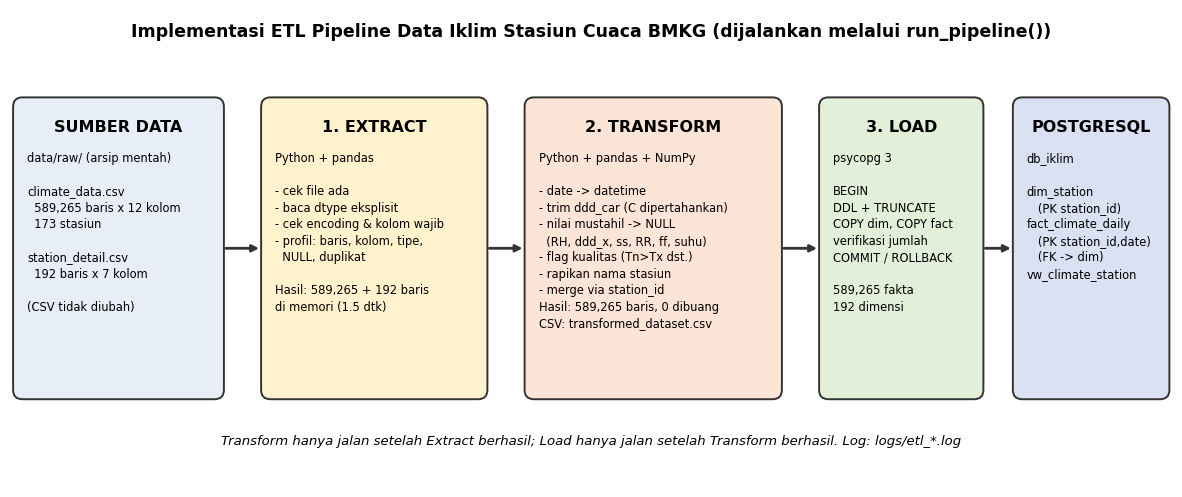

In [69]:
def draw_diagram(pipe, path):
    rep = pipe["res"]["report"]; ld = pipe["load"]
    fig, ax = plt.subplots(figsize=(15, 6.2)); ax.set_xlim(0, 15); ax.set_ylim(0, 6.2); ax.axis("off")
    def box(x, y, w, h, title, lines, color):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.06,rounding_size=0.12", fc=color, ec="#333", lw=1.4))
        ax.text(x + w/2, y + h - 0.32, title, ha="center", va="center", fontsize=11.5, fontweight="bold")
        ax.text(x + 0.12, y + h - 0.65, "\n".join(lines), ha="left", va="top", fontsize=8.3, linespacing=1.35)
    def arrow(x1, x2, y=3.1):
        ax.annotate("", xy=(x2, y), xytext=(x1, y), arrowprops=dict(arrowstyle="-|>", lw=2, color="#333"))
    box(0.1, 1.2, 2.6, 3.8, "SUMBER DATA", ["data/raw/ (arsip mentah)", "", "climate_data.csv", f"  {rep['rows_before']:,} baris x 12 kolom", f"  {rep['merge']['stations_in_climate']} stasiun",
        "", "station_detail.csv", f"  {rep['dim_rows']} baris x 7 kolom", "", "(CSV tidak diubah)"], "#E8EEF7")
    box(3.3, 1.2, 2.8, 3.8, "1. EXTRACT", ["Python + pandas", "", "- cek file ada", "- baca dtype eksplisit", "- cek encoding & kolom wajib", "- profil: baris, kolom, tipe,", "  NULL, duplikat", "", f"Hasil: {rep['rows_before']:,} + {rep['dim_rows']} baris", f"di memori ({pipe['status']['Extract']['detik']} dtk)"], "#FFF2CC")
    box(6.7, 1.2, 3.2, 3.8, "2. TRANSFORM", ["Python + pandas + NumPy", "", "- date -> datetime", "- trim ddd_car (C dipertahankan)", "- nilai mustahil -> NULL", "  (RH, ddd_x, ss, RR, ff, suhu)", "- flag kualitas (Tn>Tx dst.)", "- rapikan nama stasiun", "- merge via station_id", f"Hasil: {rep['rows_after']:,} baris, 0 dibuang", f"CSV: transformed_dataset.csv"], "#FCE4D6")
    box(10.5, 1.2, 2.0, 3.8, "3. LOAD", ["psycopg 3", "", "BEGIN", "DDL + TRUNCATE", "COPY dim, COPY fact", "verifikasi jumlah", "COMMIT / ROLLBACK", "", f"{ld['fact_rows_loaded']:,} fakta", f"{ld['dim_rows_loaded']} dimensi"], "#E2F0D9")
    box(13.0, 1.2, 1.9, 3.8, "POSTGRESQL", ["db_iklim", "", "dim_station", "   (PK station_id)", "fact_climate_daily", "   (PK station_id,date)", "   (FK -> dim)", "vw_climate_station"], "#D9E1F2")
    arrow(2.75, 3.25); arrow(6.15, 6.65); arrow(9.95, 10.45); arrow(12.55, 12.95)
    ax.text(7.5, 5.85, "Implementasi ETL Pipeline Data Iklim Stasiun Cuaca BMKG (dijalankan melalui run_pipeline())", ha="center", fontsize=12.5, fontweight="bold")
    ax.text(7.5, 0.55, "Transform hanya jalan setelah Extract berhasil; Load hanya jalan setelah Transform berhasil. Log: logs/etl_*.log", ha="center", fontsize=9.5, style="italic")
    fig.savefig(path, dpi=160, bbox_inches="tight", facecolor="white"); plt.show()

DIAGRAM_PATH = DOC_DIR / "diagram_implementasi_etl.png"
draw_diagram(pipe, DIAGRAM_PATH)

---
# 5. ETL Pipeline Testing and Validation

Setiap pengujian di bawah menghitung **hasil aktual dari data dan database**, lalu membandingkannya dengan hasil yang diharapkan.
Nilai yang diharapkan dihitung **secara independen dari data mentah** (bukan dari hasil transform yang sama), sehingga pengujian benar-benar memverifikasi.

In [82]:
hasil_uji = []
def uji(tahap, aspek, harapan, aktual, ok):
    hasil_uji.append([tahap, aspek, harapan, aktual, "Berhasil" if ok else "Gagal"])

res_p = pipe["res"]; fact_p, dim_p, merged_p, rep_p = res_p["fact"], res_p["dim"], res_p["merged"], res_p["report"]
raw = climate_raw

# ---------------- a. Extraction Testing ----------------
uji("Extract", "Akses sumber data", "Kedua file ditemukan dan tidak kosong",
    f"{sum(p.exists() and p.stat().st_size > 0 for p in (CLIMATE_FILE, STATION_FILE))}/2 file terbaca",
    CLIMATE_FILE.exists() and STATION_FILE.exists())
n_lines_climate = sum(1 for _ in open(CLIMATE_FILE, "rb")) - 1      # hitung baris file langsung (tanpa pandas)
n_lines_station = sum(1 for _ in open(STATION_FILE, "rb")) - 1
uji("Extract", "Jumlah baris = sumber", f"climate {n_lines_climate:,} & station {n_lines_station:,} baris (hitungan file)",
    f"climate {len(climate_raw):,} & station {len(station_raw):,}", (n_lines_climate, n_lines_station) == (len(climate_raw), len(station_raw)))
with open(CLIMATE_FILE, encoding="utf-8-sig") as f: hdr_c = f.readline().strip().split(",")
with open(STATION_FILE, encoding="utf-8-sig") as f: hdr_s = f.readline().strip().split(",")
uji("Extract", "Jumlah kolom & nama atribut", f"12 kolom climate, 7 kolom station (sesuai header file)",
    f"{climate_raw.shape[1]} dan {station_raw.shape[1]} kolom", hdr_c == list(climate_raw.columns) and hdr_s == list(station_raw.columns))
uji("Extract", "Atribut yang dibutuhkan lengkap", "Semua kolom wajib ada", "Lengkap" if set(CLIMATE_COLS) <= set(climate_raw.columns) and set(STATION_COLS) <= set(station_raw.columns) else "Kurang", True)

# ---------------- b. Transformation Testing ----------------
exp_nulls = {   # jumlah NULL baru yang diharapkan per kolom, dihitung dari data mentah
    "rh_avg": int((raw.RH_avg > 100).sum()), "ddd_x": int((raw.ddd_x > 360).sum()), "ss": int((raw.ss > 12).sum()),
    "rr": int(((raw.RR < 0) | (raw.RR > 500)).sum()), "ff_x": int((raw.ff_x > 60).sum()), "ff_avg": int((raw.ff_avg > 60).sum()),
    "tn": int(((raw.Tn < 5) | (raw.Tn > 45)).sum()), "tx": int(((raw.Tx < 5) | (raw.Tx > 45)).sum()),
    "tavg": int(((raw.Tavg < 5) | (raw.Tavg > 45)).sum()),
}
akt_nulls = {c: rep_p["nulls_after"][c] - rep_p["nulls_before"][c] for c in exp_nulls}
uji("Transform", "Nilai invalid ditangani (di-NULL-kan)", f"Tambahan NULL per kolom = {exp_nulls}", f"{akt_nulls}", exp_nulls == akt_nulls)
uji("Transform", "Penanganan missing values", "Tidak ada imputasi: NULL asli tetap NULL",
    f"NULL sesudah = NULL sebelum + invalid untuk semua kolom", all(rep_p["nulls_after"][c] == rep_p["nulls_before"][c] + exp_nulls.get(c, 0) for c in rep_p["nulls_after"]))
uji("Transform", "Penanganan duplikasi", "0 duplikat (station_id, date) sebelum dan sesudah",
    f"sebelum {int(raw.duplicated(['station_id','date']).sum())}, sesudah {int(fact_p.duplicated(['station_id','date']).sum())}",
    raw.duplicated(["station_id", "date"]).sum() == 0 and not fact_p.duplicated(["station_id", "date"]).any())
uji("Transform", "Konversi tipe date", "Seluruh tanggal terbaca sebagai datetime", f"{fact_p.date.dtype}; NaT = {int(fact_p.date.isna().sum())}",
    str(fact_p.date.dtype).startswith("datetime64") and fact_p.date.isna().sum() == 0)
uji("Transform", "Standardisasi ddd_car", "Tanpa spasi; nilai C dipertahankan",
    f"nilai: {sorted(fact_p.ddd_car.dropna().unique())}; C = {int((fact_p.ddd_car=='C').sum()):,}",
    set(fact_p.ddd_car.dropna().unique()) <= VALID_DIRECTIONS and int((fact_p.ddd_car == "C").sum()) == int((raw.ddd_car.str.strip() == "C").sum()))
uji("Transform", "Rentang nilai setelah cleaning", "rh 0-100, ddd_x 0-360, ss 0-12, rr 0-500, ff<=60, suhu 5-45",
    "Semua dalam rentang", all(x for x in [fact_p.rh_avg.max() <= 100, fact_p.ddd_x.max() <= 360, fact_p.ss.max() <= 12, 0 <= fact_p.rr.min(), fact_p.rr.max() <= 500,
    fact_p.ff_x.max() <= 60, fact_p.ff_avg.max() <= 60, all(fact_p[c].dropna().between(5, 45).all() for c in ["tn", "tx", "tavg"])]))
uji("Transform", "Perubahan jumlah baris", f"{len(raw):,} baris (tidak ada yang dibuang)", f"{len(fact_p):,} baris (dibuang: {len(raw) - len(fact_p)})", len(raw) == len(fact_p))
uji("Transform", "Perubahan jumlah kolom", "12 kolom -> 9 kolom flag/kualitas bertambah (21 kolom fakta)", f"{raw.shape[1]} -> {fact_p.shape[1]} kolom fakta; {merged_p.shape[1]} kolom dataset gabungan",
    fact_p.shape[1] == 21 and merged_p.shape[1] == 29)
uji("Transform", "Integrasi data (merge station_id)", "Semua baris iklim punya metadata, tanpa penggandaan baris",
    f"{rep_p['merge']['rows_merged']:,} baris tergabung, {rep_p['merge']['rows_unmatched']} tanpa metadata, merged={len(merged_p):,}",
    rep_p["merge"]["rows_unmatched"] == 0 and len(merged_p) == len(fact_p))
NAME_RE = r"\s{2,}|^\s|\s$"
bad_names = int(dim_p.station_name.str.contains(NAME_RE, regex=True).sum())
uji("Transform", "Standardisasi nama stasiun", "Tidak ada spasi ganda/tepi", f"{bad_names} nama bermasalah", bad_names == 0)
csv_back = pd.read_csv(TRANSFORMED_CSV, usecols=["station_id", "date", "rr"])
uji("Transform", "Dataset hasil transformasi tersimpan", "transformed_dataset.csv berisi jumlah baris yang sama",
    f"{len(csv_back):,} baris di CSV ({TRANSFORMED_CSV.stat().st_size/1e6:.0f} MB)", len(csv_back) == len(merged_p))


# ---------------- c. Loading Testing ----------------

uji(
    "Load",
    "Koneksi ke target storage",
    "Berhasil terhubung ke PostgreSQL Neon (neondb)",
    f"{bukti_koneksi['versi']} | db={bukti_koneksi['database']}",
    bukti_koneksi["database"] == "neondb"
)

with psycopg.connect(DATABASE_URL) as conn:
    n_fact_db = conn.execute("SELECT COUNT(*) FROM fact_climate_daily").fetchone()[0]
    n_dim_db = conn.execute("SELECT COUNT(*) FROM dim_station").fetchone()[0]
    n_view_db = conn.execute("SELECT COUNT(*) FROM vw_climate_station").fetchone()[0]
    n_orphan = conn.execute("SELECT COUNT(*) FROM fact_climate_daily f LEFT JOIN dim_station s USING (station_id) WHERE s.station_id IS NULL").fetchone()[0]
    n_dup_pk = conn.execute("SELECT COUNT(*) - COUNT(DISTINCT (station_id, date)) FROM fact_climate_daily").fetchone()[0]
    n_st_db = conn.execute("SELECT COUNT(DISTINCT station_id) FROM fact_climate_daily").fetchone()[0]

uji("Load", "Penyimpanan data",
    f"{len(fact_p):,} baris fakta dan {len(dim_p)} baris dimensi tersimpan",
    f"{n_fact_db:,} dan {n_dim_db}",
    (n_fact_db, n_dim_db) == (len(fact_p), len(dim_p)))

uji("Load", "Integritas relasi & kunci",
    "0 duplikat PK, 0 baris fakta tanpa stasiun, view = fakta",
    f"dup PK {n_dup_pk}, yatim {n_orphan}, view {n_view_db:,}",
    n_dup_pk == 0 and n_orphan == 0 and n_view_db == n_fact_db)

konsistensi2 = db_vs_pandas(fact_p)
_, _, mism2 = sample_compare(fact_p, n_stations=3, seed=7)

uji("Load", "Pembacaan kembali & kesesuaian nilai",
    "Agregat tiap kolom sama + 3 stasiun acak sama baris-per-baris",
    f"{int(konsistensi2['Cocok'].sum())}/{len(konsistensi2)} pemeriksaan agregat cocok; selisih nilai baris: {len(mism2)} kolom",
    konsistensi2["Cocok"].all() and not mism2)

# Uji idempotensi
load(fact_p, dim_p)

with psycopg.connect(DATABASE_URL) as conn:
    n_after_2 = conn.execute("SELECT COUNT(*) FROM fact_climate_daily").fetchone()[0]

uji("Load", "Idempotensi (Load dijalankan ulang)",
    f"Jumlah baris tetap {len(fact_p):,}, tidak menggandakan",
    f"{n_after_2:,} baris",
    n_after_2 == len(fact_p))

# Uji rollback
fact_bad = fact_p.copy()
fact_bad.loc[fact_bad.index[0], "rh_avg"] = 150.0

try:
    load(fact_bad, dim_p)
    rb_msg = "load tidak error (tidak diharapkan)"
except Exception as e:
    rb_msg = f"error ditangkap: {type(e).__name__}"

with psycopg.connect(DATABASE_URL) as conn:
    n_after_rb = conn.execute("SELECT COUNT(*) FROM fact_climate_daily").fetchone()[0]

uji("Load", "Keamanan transaksi (rollback)",
    "Data buruk ditolak dan data lama utuh",
    f"{rb_msg}; baris tetap {n_after_rb:,}",
    "error" in rb_msg and n_after_rb == len(fact_p))

# ---------------- d. End-to-End Testing ----------------
st_ = pipe["status"]
uji("End-to-End", "Eksekusi pipeline utuh", "Extract, Transform, Load semuanya BERHASIL, berurutan", " | ".join(f"{k}: {v['status']} ({v['detik']} dtk)" for k, v in st_.items()),
    all(v["status"] == "BERHASIL" for v in st_.values()))
uji("End-to-End", "Output antar tahap menyambung", "Jumlah baris sama di Extract, Transform, dan Load", f"{pipe['counts']['extract']:,} -> {pipe['counts']['transform']:,} -> {pipe['counts']['load']:,}",
    len(set(pipe["counts"].values())) == 1)
_backup = CLIMATE_FILE
CLIMATE_FILE = RAW_DIR / "file_tidak_ada.csv"                 # simulasi kegagalan di tahap Extract
gagal = run_pipeline()
CLIMATE_FILE = _backup
uji("End-to-End", "Urutan eksekusi saat Extract gagal", "Transform dan Load TIDAK dijalankan", " | ".join(f"{k}: {v['status']}" for k, v in gagal["status"].items()),
    [v["status"] for v in gagal["status"].values()] == ["GAGAL", "TIDAK DIJALANKAN", "TIDAK DIJALANKAN"])
with psycopg.connect(DATABASE_URL) as conn:
    n_after_fail = conn.execute("SELECT COUNT(*) FROM fact_climate_daily").fetchone()[0]
uji("End-to-End", "Data di target tetap utuh setelah run gagal", f"Tetap {len(fact_p):,} baris", f"{n_after_fail:,} baris", n_after_fail == len(fact_p))
uji("End-to-End", "Hasil akhir sesuai kebutuhan studi kasus", f"173 stasiun terhubung ke 192 metadata, siap dashboard (view)", f"{n_st_db} stasiun di fakta; {n_dim_db} di dimensi; view {n_view_db:,} baris",
    n_st_db == rep_p["merge"]["stations_merged"] and n_view_db == n_fact_db)

tabel_uji = pd.DataFrame(hasil_uji, columns=["Tahapan", "Aspek yang Diuji", "Hasil yang Diharapkan", "Hasil Aktual", "Status"])
print(f"Ringkasan: {int((tabel_uji.Status == 'Berhasil').sum())} dari {len(tabel_uji)} pengujian BERHASIL")
tabel_uji

16:51:44 | INFO    | Proses Load dimulai
16:51:57 | INFO    | Data berhasil disimpan ke Neon: dim_station=192, fact_climate_daily=589,265
16:51:57 | INFO    | Proses Load dimulai
16:52:08 | INFO    | ETL Pipeline dimulai
16:52:08 | INFO    | Proses Extract dimulai
16:52:08 | ERROR   | Tahap Extract GAGAL: FileNotFoundError: File tidak ditemukan: /content/Tugas_Minggu10_Kelompok2/Dataset/raw/file_tidak_ada.csv
16:52:08 | INFO    | ETL Pipeline selesai dijalankan | {'Extract': 'GAGAL', 'Transform': 'TIDAK DIJALANKAN', 'Load': 'TIDAK DIJALANKAN'}
Ringkasan: 26 dari 26 pengujian BERHASIL


,Tahapan,Aspek yang Diuji,Hasil yang Diharapkan,Hasil Aktual,Status
0,Extract,Akses sumber data,Kedua file ditemukan dan tidak kosong,2/2 file terbaca,Berhasil
1,Extract,Jumlah baris = sumber,"climate 589,265 & station 192 baris (hitungan file)","climate 589,265 & station 192",Berhasil
2,Extract,Jumlah kolom & nama atribut,"12 kolom climate, 7 kolom station (sesuai header file)",12 dan 7 kolom,Berhasil
3,Extract,Atribut yang dibutuhkan lengkap,Semua kolom wajib ada,Lengkap,Berhasil
4,Transform,Nilai invalid ditangani (di-NULL-kan),"Tambahan NULL per kolom = {'rh_avg': 7, 'ddd_x': 541, 'ss': 206, 'rr': 11, '...","{'rh_avg': 7, 'ddd_x': 541, 'ss': 206, 'rr': 11, 'ff_x': 51, 'ff_avg': 12, '...",Berhasil
5,Transform,Penanganan missing values,Tidak ada imputasi: NULL asli tetap NULL,NULL sesudah = NULL sebelum + invalid untuk semua kolom,Berhasil
6,Transform,Penanganan duplikasi,"0 duplikat (station_id, date) sebelum dan sesudah","sebelum 0, sesudah 0",Berhasil
7,Transform,Konversi tipe date,Seluruh tanggal terbaca sebagai datetime,datetime64[ns]; NaT = 0,Berhasil
8,Transform,Standardisasi ddd_car,Tanpa spasi; nilai C dipertahankan,"nilai: ['C', 'E', 'N', 'NE', 'NW', 'S', 'SE', 'SW', 'W']; C = 55,370",Berhasil
9,Transform,Rentang nilai setelah cleaning,"rh 0-100, ddd_x 0-360, ss 0-12, rr 0-500, ff<=60, suhu 5-45",Semua dalam rentang,Berhasil


### 5e. Jumlah data pada setiap tahapan

In [72]:
tabel_jumlah = pd.DataFrame([
    ["Setelah Extract", f"{pipe['counts']['extract']:,}", "Data awal dari sumber (climate_data.csv); metadata stasiun 192 baris"],
    ["Setelah Transform", f"{pipe['counts']['transform']:,}", "Setelah cleaning dan transformasi; tidak berubah karena nilai invalid hanya di-NULL-kan, tidak ada duplikat"],
    ["Setelah Load", f"{n_fact_db:,}", f"fact_climate_daily; dim_station = {n_dim_db} baris (192 metadata, 19 di antaranya tanpa data iklim)"],
], columns=["Tahapan", "Jumlah Baris", "Keterangan"])
display(tabel_jumlah)
print("Tidak ada perbedaan jumlah baris antar tahapan (0 baris hilang).")

# ---- Simpan seluruh hasil untuk dokumentasi ----
hasil = {
    "lingkungan": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
                   "psycopg": psycopg.__version__, "postgres": bukti_koneksi["versi"], "waktu_run": f"{datetime.now():%d-%m-%Y %H:%M}"},
    "sumber": sumber.to_dict("records"), "extract": extract_summary, "problems": problems.to_dict("records"),
    "validasi": validasi.to_dict("records"), "umum": umum.astype(str).to_dict("records"), "report": rep_p,
    "status": pipe["status"], "counts": pipe["counts"], "load_seconds": load_seconds,
    "konsistensi": konsistensi2.astype(str).to_dict("records"), "tabel_uji": tabel_uji.to_dict("records"),
    "struktur": struktur.to_dict("records"), "contoh_db": contoh.astype(str).to_dict("records"),
    "contoh_transform": merged_p.head(5).astype(str).to_dict("records"),
    "contoh_extract": climate_raw.head(5).astype(str).to_dict("records"),
    "csv_mb": round(TRANSFORMED_CSV.stat().st_size / 1e6, 1),
}
(DOC_DIR / "hasil_eksekusi.json").write_text(json.dumps(hasil, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
print("Hasil eksekusi disimpan ke Documentation/hasil_eksekusi.json")

,Tahapan,Jumlah Baris,Keterangan
0,Setelah Extract,"589,265",Data awal dari sumber (climate_data.csv); metadata stasiun 192 baris
1,Setelah Transform,"589,265",Setelah cleaning dan transformasi; tidak berubah karena nilai invalid hanya ...
2,Setelah Load,"589,265","fact_climate_daily; dim_station = 192 baris (192 metadata, 19 di antaranya t..."


Tidak ada perbedaan jumlah baris antar tahapan (0 baris hilang).
Hasil eksekusi disimpan ke Documentation/hasil_eksekusi.json


---
# 6. Kesimpulan

In [83]:
semua_ok = (tabel_uji.Status == "Berhasil").all()
print(f"Status keseluruhan: {'ETL PIPELINE BERHASIL' if semua_ok else 'ADA PENGUJIAN GAGAL'}")
print(f"- Extract   : {len(climate_raw):,} baris iklim + {len(station_raw)} stasiun berhasil dibaca dan diprofilkan.")
print(f"- Transform : {sum(v for k, v in rep_p['invalid_by_rule'].items() if 'flag' not in k and 'dibuang' not in k and 'tn > tx' not in k):,} nilai invalid di-NULL-kan, "
      f"{rep_p['rows_with_dq_issue']:,} baris diberi flag, 0 baris dibuang.")
print(f"- Load      : {n_fact_db:,} baris fakta dan {n_dim_db} baris dimensi tersimpan di PostgreSQL dan terbukti identik saat dibaca kembali.")
print(f"- Pengujian : {int((tabel_uji.Status == 'Berhasil').sum())}/{len(tabel_uji)} lulus.")
assert semua_ok

Status keseluruhan: ETL PIPELINE BERHASIL
- Extract   : 589,265 baris iklim + 192 stasiun berhasil dibaca dan diprofilkan.
- Transform : 987 nilai invalid di-NULL-kan, 1,453 baris diberi flag, 0 baris dibuang.
- Load      : 589,265 baris fakta dan 192 baris dimensi tersimpan di PostgreSQL dan terbukti identik saat dibaca kembali.
- Pengujian : 26/26 lulus.


In [75]:
# Menampilkan pengujian yang gagal saja
uji_gagal = tabel_uji[tabel_uji["Status"] == "Gagal"]

display(uji_gagal)

,Tahapan,Aspek yang Diuji,Hasil yang Diharapkan,Hasil Aktual,Status
15,Load,Koneksi ke target storage,Berhasil terhubung ke PostgreSQL db_iklim,PostgreSQL 18.7 (a21afb5) on aarch64-unknown-linux-gnu | db=neondb,Gagal


In [76]:
display(
    tabel_uji[["Tahapan", "Aspek yang Diuji", "Status"]]
)

,Tahapan,Aspek yang Diuji,Status
0,Extract,Akses sumber data,Berhasil
1,Extract,Jumlah baris = sumber,Berhasil
2,Extract,Jumlah kolom & nama atribut,Berhasil
3,Extract,Atribut yang dibutuhkan lengkap,Berhasil
4,Transform,Nilai invalid ditangani (di-NULL-kan),Berhasil
5,Transform,Penanganan missing values,Berhasil
6,Transform,Penanganan duplikasi,Berhasil
7,Transform,Konversi tipe date,Berhasil
8,Transform,Standardisasi ddd_car,Berhasil
9,Transform,Rentang nilai setelah cleaning,Berhasil
